# Etapa 2: Transformação numérica e redução de dimensionalidade

Nesta parte da Etapa 2 eu cuido da escala dos atributos numéricos. Parti da base limpa da Pessoa 1 (`treino_limpo.csv`) e comparei, sempre com validação cruzada e F1-macro:

1. **transformação** com `log1p` nos atributos muito assimétricos (bytes e duração, como pede o enunciado, e uma variante com todas as contagens);
2. **escala** com `StandardScaler` × `RobustScaler` (e sem escala, como referência);
3. **redução de dimensionalidade** com PCA.

Tudo fica dentro de um `Pipeline`, então o `log1p`, os escaladores e o PCA só são ajustados no treino de cada fold. As peças ficam no arquivo `transformacao.py`, para a Pessoa 4 juntar no notebook final.

## 0. Leitura dos dados e avaliação

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

import transformacao as T   # as peças desta parte ficam em transformacao.py

pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
treino_limpo = pd.read_csv(PASTA / "treino_limpo.csv")
X, y = T.separar(treino_limpo)         # tira class e score_ids_legado
NUM = T.colunas_numericas(X)

print("X:", X.shape, f"| anomalias: {y.mean() * 100:.2f}%")
print(f"{len(NUM)} numéricas e {len(T.CATEGORICAS)} categóricas")

X: (55074, 40) | anomalias: 3.30%
37 numéricas e 3 categóricas


Deixei `score_ids_legado` de fora de propósito: o grupo ainda não decidiu se ela é vazamento, e se ela for muito forte pode esconder a diferença entre as técnicas que quero comparar.

**Avaliação.** A função `avaliar(pipeline)` da Pessoa 1 ainda não está pronta, então uso uma provisória com o mesmo protocolo combinado: validação cruzada estratificada com 5 folds (embaralhada, `random_state=42`) e F1-macro. Ela se chama `avaliar_p3` para não tapar a da Pessoa 1 no notebook do grupo; quando a dela sair, é só trocar.

**Modelos.** Escala e PCA só fazem diferença para modelos sensíveis à escala, então comparo dois deles: **regressão logística** (linear, otimizada por gradiente) e **KNN** (baseado em distância). Árvores não mudam com transformações crescentes como essas, por isso ficaram de fora desta comparação. A imputação (mediana / mais frequente) e a codificação (one-hot) são provisórias, iguais em todas as rodadas, e serão trocadas pela escolha da Pessoa 2.

In [2]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# provisória, até a avaliar() da Pessoa 1 ficar pronta
def avaliar_p3(pipeline, X=X, y=y):
    r = cross_validate(pipeline, X, y, cv=CV, scoring="f1_macro", n_jobs=-1, return_estimator=True)
    return {"f1_macro": r["test_score"].mean(), "desvio": r["test_score"].std(),
            "treino_s": r["fit_time"].mean(), "previsao_s": r["score_time"].mean(),
            "estimadores": r["estimator"]}

MODELOS = {
    "Regressão logística": lambda: LogisticRegression(max_iter=2000),
    "KNN (k=5)": lambda: KNeighborsClassifier(n_neighbors=5),
}

## 1. Por que `log1p`?

Antes de transformar, olho a assimetria (*skewness*) das numéricas. Uma distribuição simétrica tem assimetria perto de 0; acima de 1 já é bem assimétrica. O `log1p(x) = log(1 + x)` comprime os valores grandes e funciona com zero, que é o valor mais comum nessas colunas.

In [3]:
assim = X[NUM].skew()
resumo = pd.DataFrame({
    "assimetria": assim,
    "% zeros": (X[NUM] == 0).mean() * 100,
    "mediana": X[NUM].median(),
    "máximo": X[NUM].max(),
}).sort_values("assimetria", ascending=False)
resumo["log1p na variante contagens"] = resumo.index.isin(T.COLS_LOG_CONTAGENS)
display(resumo.round(2).head(20))
print("colunas 0/1:", [c for c in NUM if set(X[c].dropna().unique()) <= {0, 1}])

,assimetria,% zeros,mediana,máximo,log1p na variante contagens
is_host_login,234.68,100.00,0.0,1.0,False
dst_bytes,215.03,17.28,386.0,209228000.0,True
duration,182.59,87.48,0.0,39603000.0,True
num_root,177.83,99.20,0.0,7468.0,True
urgent,149.46,99.99,0.0,3.0,True
src_bytes,101.58,4.30,227.0,21945520.0,True
land,88.69,99.99,0.0,1.0,False
num_file_creations,65.44,94.39,0.0,100.0,True
num_shells,49.69,99.95,0.0,2.0,True
num_compromised,49.39,93.23,0.0,10300.0,True


colunas 0/1: ['land', 'logged_in', 'root_shell', 'su_attempted', 'is_host_login', 'is_guest_login']


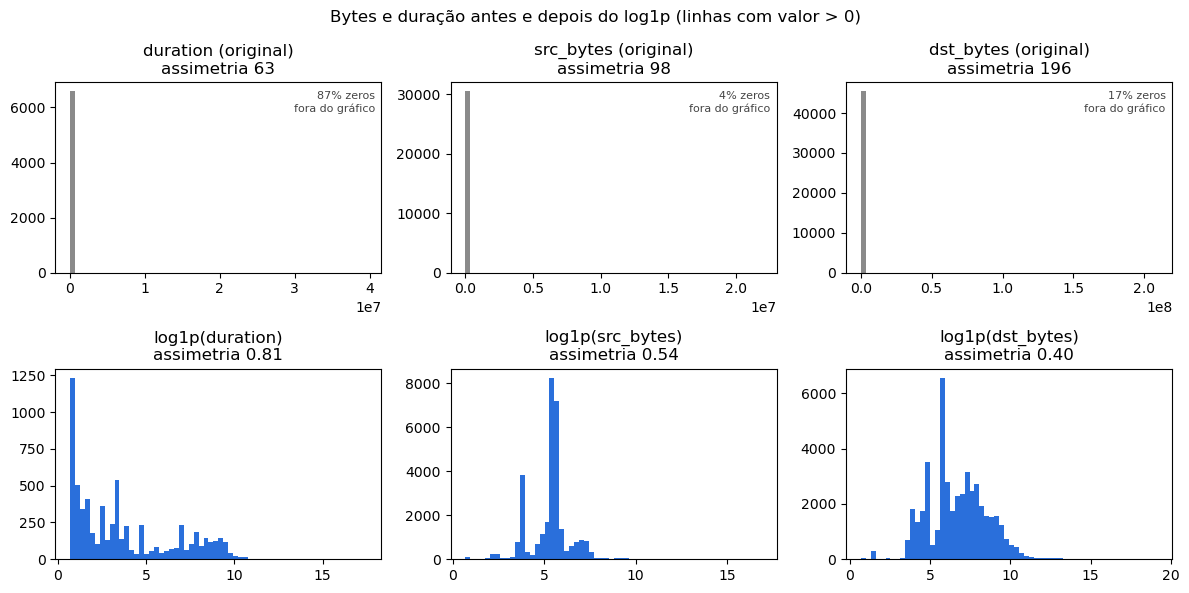

In [4]:
# gráfico 1: bytes e duração antes e depois do log1p (só valores > 0, senão o zero domina)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, c in enumerate(T.COLS_LOG_BYTES):
    v = X[c].dropna()
    v = v[v > 0]
    axes[0, j].hist(v, bins=60, color=CINZA)
    axes[0, j].set_title(f"{c} (original)\nassimetria {v.skew():.0f}")
    axes[1, j].hist(np.log1p(v), bins=60, color=AZUL)
    axes[1, j].set_title(f"log1p({c})\nassimetria {np.log1p(v).skew():.2f}")
    axes[0, j].text(0.98, 0.95, f"{(X[c] == 0).mean():.0%} zeros\nfora do gráfico", transform=axes[0, j].transAxes,
                    ha="right", va="top", fontsize=8, color="#444")
fig.suptitle("Bytes e duração antes e depois do log1p (linhas com valor > 0)")
plt.tight_layout(); plt.show()

**Conclusão da seção 1**

- Os bytes e a duração estão entre as colunas mais assimétricas da base: `dst_bytes` tem assimetria 215, `duration` 183 e `src_bytes` 102. Os máximos chegam a 209 milhões de bytes e 39,6 milhões de segundos, enquanto as medianas são 386, 0 e 227.
- Olhando só os valores acima de zero, o `log1p` derruba a assimetria para menos de 1 nas três (0,81 na duração, 0,54 em `src_bytes` e 0,40 em `dst_bytes`). O gráfico mostra a diferença: antes quase tudo fica espremido numa barra perto do zero; depois aparece a distribuição de verdade.
- `duration` é zero em 87% das linhas. O `log1p` mantém o zero como zero, então essas linhas não mudam.
- Outras contagens também são muito assimétricas (`num_root`, `num_compromised`, `num_file_creations`, `hot`...). Por isso testo também uma variante com `log1p` em **todas as contagens** (16 colunas que não são taxa nem 0/1). As taxas já ficam entre 0 e 1 e as seis colunas 0/1 não têm o que comprimir, então ficam de fora.

## 2. Por que o `RobustScaler` pode não ajudar aqui

O `StandardScaler` subtrai a média e divide pelo desvio padrão. O `RobustScaler` subtrai a mediana e divide pelo intervalo interquartil (IQR = Q3 − Q1), que não é afetado por valores extremos. O problema é quando o IQR é **zero**: aí o sklearn não divide por nada (escala 1), e a coluna fica com os valores originais. Conto quantas colunas estão nessa situação.

In [5]:
q1, q3 = X[NUM].quantile(0.25), X[NUM].quantile(0.75)
iqr = q3 - q1
iqr_zero = iqr[iqr == 0].index.tolist()
print(f"{len(iqr_zero)} de {len(NUM)} numéricas têm IQR = 0")
display(pd.DataFrame({"IQR": iqr[iqr_zero], "máximo": X[iqr_zero].max()})
        .sort_values("máximo", ascending=False).head(10))

25 de 37 numéricas têm IQR = 0


,IQR,máximo
duration,0.0,39603000.0
num_compromised,0.0,10300.0
num_root,0.0,7468.0
hot,0.0,101.0
num_file_creations,0.0,100.0
num_access_files,0.0,9.0
num_failed_logins,0.0,4.0
urgent,0.0,3.0
wrong_fragment,0.0,3.0
num_shells,0.0,2.0


**Conclusão da seção 2**

- 25 das 37 numéricas têm IQR = 0, porque mais de 75% das linhas têm o mesmo valor (quase sempre zero). Nelas o `RobustScaler` só subtrai a mediana e **não muda a escala**.
- Entre elas estão justamente as colunas com valores extremos: `duration` (até 39,6 milhões), `num_compromised` (até 10.300) e `num_root` (até 7.468). Sem `log1p`, esses valores entram no modelo praticamente do jeito que vieram, e a expectativa é que o `RobustScaler` vá mal nesse caso. A seção 3 confirma.

## 3. Comparação: `log1p` × escala

Cruzo três opções de `log1p` (nenhum, só bytes e duração, todas as contagens) com três de escala (nenhuma, `StandardScaler`, `RobustScaler`), nos dois modelos. São 18 combinações, cada uma com 5 folds. O que muda entre elas é só o bloco numérico; imputação, one-hot e modelo são os mesmos.

In [6]:
OPCOES_LOG = {
    "sem log1p": [],
    "log1p bytes e duração": T.COLS_LOG_BYTES,
    "log1p todas as contagens": T.COLS_LOG_CONTAGENS,
}
ESCALAS = {"sem escala": "nenhum", "StandardScaler": "standard", "RobustScaler": "robust"}

linhas = []
for nome_m, modelo in MODELOS.items():
    for nome_log, cols in OPCOES_LOG.items():
        for nome_esc, esc in ESCALAS.items():
            pipe = Pipeline([("pre", T.montar_preprocessador(cols, esc)), ("modelo", modelo())])
            r = avaliar_p3(pipe)
            linhas.append({"modelo": nome_m, "log1p": nome_log, "escala": nome_esc,
                           "f1_macro": r["f1_macro"], "desvio": r["desvio"], "treino_s": r["treino_s"]})
comp = pd.DataFrame(linhas)

# tabela: F1-macro médio ± desvio entre os folds
comp["F1-macro"] = comp["f1_macro"].map("{:.4f}".format) + " ± " + comp["desvio"].map("{:.4f}".format)
tabela = comp.pivot(index=["modelo", "log1p"], columns="escala", values="F1-macro")
display(tabela.loc[[(m, l) for m in MODELOS for l in OPCOES_LOG], list(ESCALAS)])

melhor = comp.loc[comp.groupby("modelo")["f1_macro"].idxmax(), ["modelo", "log1p", "escala", "f1_macro"]]
display(melhor.round(4).reset_index(drop=True))

# tempo médio de treino por fold (s) na regressão logística: sem escala o otimizador demora a convergir
display(comp[comp["modelo"] == "Regressão logística"]
        .pivot(index="log1p", columns="escala", values="treino_s").loc[list(OPCOES_LOG), list(ESCALAS)].round(1))

escala                                             sem escala  \
modelo              log1p                                       
Regressão logística sem log1p                 0.8903 ± 0.0084   
                    log1p bytes e duração     0.9314 ± 0.0043   
                    log1p todas as contagens  0.9379 ± 0.0023   
KNN (k=5)           sem log1p                 0.9003 ± 0.0052   
                    log1p bytes e duração     0.8810 ± 0.0080   
                    log1p todas as contagens  0.9511 ± 0.0078   

escala                                         StandardScaler     RobustScaler  
modelo              log1p                                                       
Regressão logística sem log1p                 0.9300 ± 0.0043  0.8436 ± 0.0363  
                    log1p bytes e duração     0.9336 ± 0.0031  0.9323 ± 0.0037  
                    log1p todas as contagens  0.9373 ± 0.0013  0.9387 ± 0.0026  
KNN (k=5)           sem log1p                 0.9512 ± 0.0065  0.9137 ± 0.0054  
                    log1p bytes e duração     0.9523 ± 0.0075  0.9235 ± 0.0078  
                    log1p todas as contagens  0.9588 ± 0.0053  0.9289 ± 0.0053

,modelo,log1p,escala,f1_macro
0,KNN (k=5),log1p todas as contagens,StandardScaler,0.9588
1,Regressão logística,log1p todas as contagens,RobustScaler,0.9387


escala,sem escala,StandardScaler,RobustScaler
log1p,,,
sem log1p,45.4,2.3,46.2
log1p bytes e duração,40.3,2.3,18.4
log1p todas as contagens,2.5,2.3,13.4


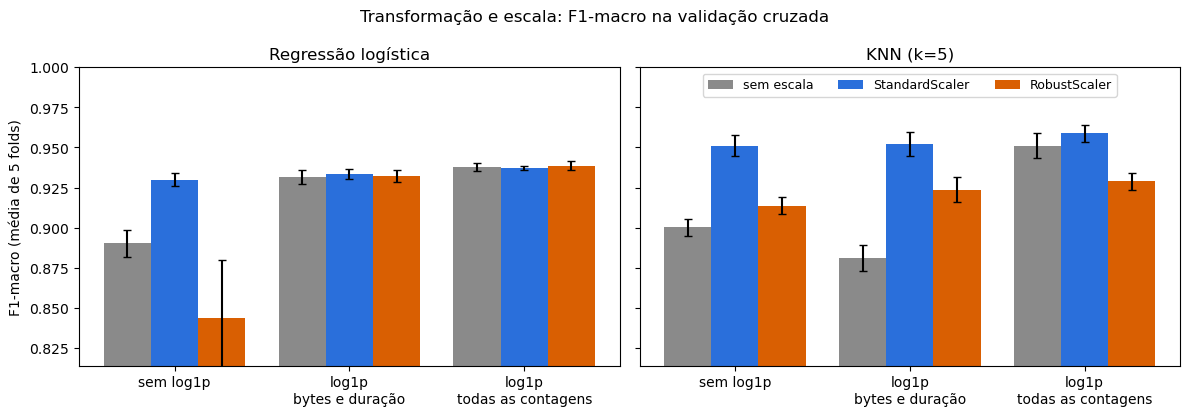

In [7]:
# gráfico 2: F1-macro de cada combinação, com o desvio entre os folds
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
cores = {"sem escala": CINZA, "StandardScaler": AZUL, "RobustScaler": LARANJA}
x = np.arange(len(OPCOES_LOG))
for ax, nome_m in zip(axes, MODELOS):
    sub = comp[comp["modelo"] == nome_m]
    for k, esc in enumerate(ESCALAS):
        s = sub[sub["escala"] == esc]
        ax.bar(x + (k - 1) * 0.27, s["f1_macro"], 0.27, yerr=s["desvio"], capsize=3, color=cores[esc], label=esc)
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace("log1p ", "log1p\n") for n in OPCOES_LOG])
    ax.set_title(nome_m)
axes[0].set_ylim(comp["f1_macro"].min() - 0.03, 1)
axes[0].set_ylabel("F1-macro (média de 5 folds)")
axes[1].legend(loc="upper center", ncol=3, fontsize=9)
fig.suptitle("Transformação e escala: F1-macro na validação cruzada")
plt.tight_layout(); plt.show()

**Conclusão da seção 3**

- **O `log1p` ajudou nos dois modelos.** O melhor resultado de cada modelo usa `log1p` em todas as contagens: 0,9588 no KNN (com `StandardScaler`) e 0,9387 na regressão logística (com `RobustScaler`). Só bytes e duração já ajudam, mas a variante com todas as contagens é melhor em quase todas as combinações.
- **Sem `log1p`, o `RobustScaler` é a pior opção:** 0,8436 na regressão logística (com o maior desvio da tabela, 0,036) e 0,9137 no KNN, abaixo até de não escalar no caso da logística. É o efeito da seção 2: com IQR = 0 os valores extremos não são reduzidos. Com o `log1p` antes, os extremos já ficam pequenos e o `RobustScaler` se recupera na logística (0,9387).
- **Na regressão logística, depois do `log1p` em todas as contagens, a escala quase não importa:** 0,9379 (sem escala), 0,9373 (Standard) e 0,9387 (Robust), diferenças menores que o desvio entre os folds. A escala aparece no tempo: sem `log1p`, a logística leva cerca de 40 s por fold sem escala ou com `RobustScaler`, contra uns 2 s com `StandardScaler`, porque com valores enormes o otimizador demora a convergir. Com `log1p` em todas as contagens, sem escala e `StandardScaler` ficam em uns 2 s e o `RobustScaler` em pouco mais de 10 s (os tempos variam um pouco a cada execução).
- **No KNN a escala importa muito, e o `StandardScaler` é sempre o melhor**, cerca de 0,03 acima do `RobustScaler`. O KNN mede distâncias, e o `StandardScaler` coloca todas as colunas com desvio 1, inclusive as 25 de IQR = 0, que o `RobustScaler` deixa como estão. Sem escala, o resultado depende das unidades: com `log1p` só nos bytes ele piora (0,8810), porque aí as contagens que vão até 511 passam a dominar a distância.

**Escolha:** `log1p` em todas as contagens + `StandardScaler` (`T.montar_preprocessador(T.COLS_LOG_CONTAGENS, "standard")`). É o melhor no KNN com folga e, na logística, fica empatado com os outros dentro do desvio. É essa configuração que uso como base para o PCA na próxima seção.

## 4. Redução de dimensionalidade com PCA

Depois do pré-processamento escolhido, cada linha vira um vetor com as 37 numéricas mais as colunas do one-hot. O PCA troca essas colunas por um número menor de combinações lineares delas (os componentes), escolhidas para guardar o máximo possível da **variância**. É não supervisionado: não olha a classe. Como depende da escala, ele entra depois do `StandardScaler`.

Primeiro vejo quantos componentes são precisos para guardar 80%, 90%, 95% e 99% da variância. Esse ajuste no treino inteiro serve só para o gráfico; na avaliação o PCA é ajustado dentro de cada fold, como o resto.

colunas depois do pré-processamento: 116
componentes para guardar a variância: {'80%': 18, '90%': 24, '95%': 28, '99%': 37}


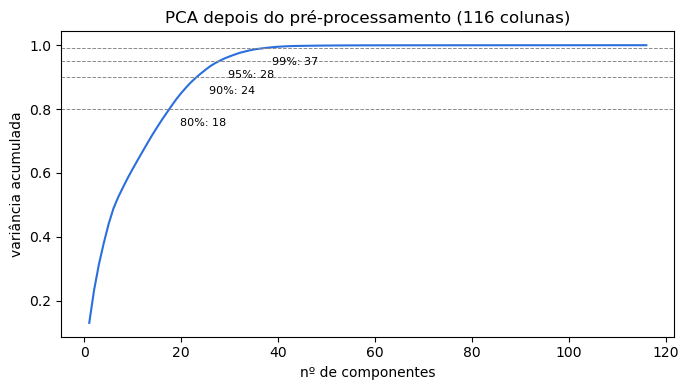

In [8]:
PRE_ESCOLHIDO = dict(cols_log=T.COLS_LOG_CONTAGENS, escalador="standard")

Z = T.montar_preprocessador(**PRE_ESCOLHIDO).fit_transform(X)
var_acum = np.cumsum(PCA().fit(Z).explained_variance_ratio_)
n_para = {f"{q:.0%}": int(np.searchsorted(var_acum, q) + 1) for q in [0.80, 0.90, 0.95, 0.99]}
print("colunas depois do pré-processamento:", Z.shape[1])
print("componentes para guardar a variância:", n_para)

# gráfico 3: variância acumulada
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(var_acum) + 1), var_acum, color=AZUL)
for q, k in n_para.items():
    ax.axhline(float(q[:-1]) / 100, color=CINZA, lw=0.7, ls="--")
    ax.annotate(f"{q}: {k}", (k, float(q[:-1]) / 100), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.set_xlabel("nº de componentes")
ax.set_ylabel("variância acumulada")
ax.set_title(f"PCA depois do pré-processamento ({Z.shape[1]} colunas)")
plt.tight_layout(); plt.show()

Agora comparo, nos dois modelos, o pipeline sem PCA com o PCA guardando 90%, 95% e 99% da variância, e com números fixos de componentes (5, 10 e 20). Além do F1-macro, olho o tempo de previsão, que é onde o PCA costuma ajudar o KNN (menos colunas, distâncias mais baratas).

In [9]:
def n_colunas(est):
    # quantas colunas chegam no modelo (pré-processamento aplicado numa linha)
    return est[:-1].transform(X.head(1)).shape[1]

OPCOES_PCA = {"sem PCA": None, "PCA 90%": 0.90, "PCA 95%": 0.95, "PCA 99%": 0.99,
              "PCA 5": 5, "PCA 10": 10, "PCA 20": 20}

linhas = []
for nome_m, modelo in MODELOS.items():
    for nome_p, k in OPCOES_PCA.items():
        pre = T.montar_preprocessador(**PRE_ESCOLHIDO)
        if k is not None:
            pre = T.com_pca(pre, k)
        r = avaliar_p3(Pipeline([("pre", pre), ("modelo", modelo())]))
        linhas.append({"modelo": nome_m, "PCA": nome_p, "colunas": n_colunas(r["estimadores"][0]),
                       "f1_macro": r["f1_macro"], "desvio": r["desvio"], "previsao_s": r["previsao_s"]})
pca_tudo = pd.DataFrame(linhas)
display(pca_tudo.round(4))

,modelo,PCA,colunas,f1_macro,desvio,previsao_s
0,Regressão logística,sem PCA,116,0.9373,0.0013,0.0616
1,Regressão logística,PCA 90%,24,0.9033,0.0029,0.0726
2,Regressão logística,PCA 95%,28,0.9053,0.0040,0.0720
3,Regressão logística,PCA 99%,37,0.9041,0.0036,0.0754
4,Regressão logística,PCA 5,5,0.9011,0.0037,0.0651
5,Regressão logística,PCA 10,10,0.8957,0.0057,0.0722
6,Regressão logística,PCA 20,20,0.8922,0.0066,0.0677
7,KNN (k=5),sem PCA,116,0.9588,0.0053,9.8822
8,KNN (k=5),PCA 90%,24,0.9506,0.0071,3.9200
9,KNN (k=5),PCA 95%,28,0.9518,0.0082,4.1160


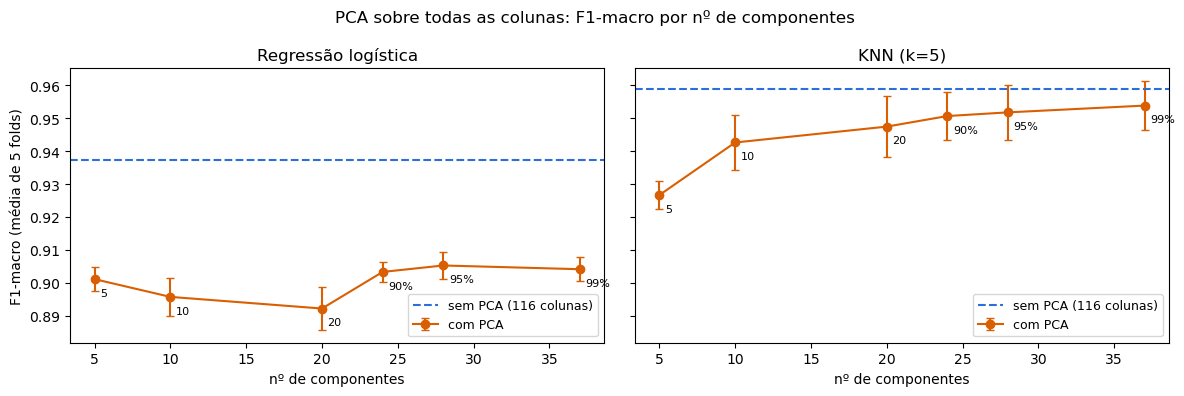

In [10]:
# gráfico 4: F1-macro x nº de colunas que chegam no modelo
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, nome_m in zip(axes, MODELOS):
    s = pca_tudo[(pca_tudo["modelo"] == nome_m) & (pca_tudo["PCA"] != "sem PCA")].sort_values("colunas")
    base = pca_tudo[(pca_tudo["modelo"] == nome_m) & (pca_tudo["PCA"] == "sem PCA")].iloc[0]
    ax.errorbar(s["colunas"], s["f1_macro"], yerr=s["desvio"], marker="o", capsize=3, color=LARANJA, label="com PCA")
    ax.axhline(base["f1_macro"], color=AZUL, ls="--", label=f"sem PCA ({base['colunas']} colunas)")
    for _, l in s.iterrows():
        ax.annotate(l["PCA"].replace("PCA ", ""), (l["colunas"], l["f1_macro"]), xytext=(4, -12), textcoords="offset points", fontsize=8)
    ax.set_xlabel("nº de componentes")
    ax.set_title(nome_m)
    ax.legend(loc="lower right", fontsize=9)
axes[0].set_ylabel("F1-macro (média de 5 folds)")
fig.suptitle("PCA sobre todas as colunas: F1-macro por nº de componentes")
plt.tight_layout(); plt.show()

**Conclusão da seção 4**

- Depois do pré-processamento são 116 colunas (37 numéricas e 79 do one-hot). Com 28 componentes o PCA já guarda 95% da variância, e com 37, 99%: dá para reduzir as colunas em mais de 3 vezes "perdendo" pouca variância.
- **Mas o F1-macro caiu nos dois modelos, com qualquer número de componentes.** Na regressão logística a queda é grande: de 0,9373 sem PCA para no máximo 0,9053 (95%), mais de 0,03 e muito acima do desvio entre os folds. Guardar 99% da variância (0,9041) não ajuda em nada em relação a 90% (0,9033).
- No KNN a queda é menor (0,9588 sem PCA, 0,9538 com 99%), mas também existe. Com poucos componentes ela cresce: 0,9266 com 5.
- O ganho do PCA foi de tempo no KNN: com 95% da variância a previsão de um fold cai de uns 10 s para uns 4 s. Na regressão logística o tempo já é desprezível.
- Perder 1% da variância e 0,03 de F1 ao mesmo tempo indica que a informação útil está justamente nas direções de **pouca** variância. A seção 5 mostra quais são.

## 5. Por que o PCA perdeu informação

O PCA guarda as direções de maior variância, mas **variância não é o mesmo que poder de separar as classes**. Depois do `StandardScaler`, cada numérica tem variância 1. Já uma coluna do one-hot com proporção *p* de uns tem variância *p*(1 − *p*), que é muito pequena para as categorias raras. Comparo quanto da variância total vem de cada grupo e se as categorias de `service` dizem algo sobre a classe.

In [11]:
n_num = len(NUM)
var_col = Z.var(axis=0)
print(f"variância total: {var_col.sum():.1f}")
print(f"  numéricas ({n_num} colunas): {var_col[:n_num].sum():.1f} ({var_col[:n_num].sum() / var_col.sum():.1%})")
print(f"  one-hot ({Z.shape[1] - n_num} colunas): {var_col[n_num:].sum():.1f} ({var_col[n_num:].sum() / var_col.sum():.1%})")

# serviços com mais anomalias: são categorias pequenas, mas quase só de ataque
por_servico = treino_limpo.groupby("service")["class"].agg(linhas="size", pct_anomalias=lambda s: (s == "anomaly").mean() * 100)
por_servico["variância no one-hot"] = (por_servico["linhas"] / len(treino_limpo)) * (1 - por_servico["linhas"] / len(treino_limpo))
display(por_servico[por_servico["linhas"] >= 30].sort_values("pct_anomalias", ascending=False).head(8).round(4))

variância total: 38.1
  numéricas (37 colunas): 37.0 (97.2%)
  one-hot (79 colunas): 1.1 (2.8%)


,linhas,pct_anomalias,variância no one-hot
service,,,
domain,34,41.1765,0.0006
private,1762,34.4495,0.0310
ecr_i,212,32.5472,0.0038
eco_i,402,25.1244,0.0072
time,59,20.3390,0.0011
pop_3,148,12.8378,0.0027
telnet,672,10.7143,0.0121
auth,171,10.5263,0.0031


Se o problema é o PCA misturar as colunas do one-hot com as numéricas, a solução é aplicar o PCA **só nas numéricas** e deixar o one-hot passar direto. É o que faz `T.montar_preprocessador(..., pca_numericas=k)`.

In [12]:
linhas = []
for nome_m, modelo in MODELOS.items():
    for nome_p, k in [("PCA 90% (só numéricas)", 0.90), ("PCA 95% (só numéricas)", 0.95), ("PCA 99% (só numéricas)", 0.99)]:
        r = avaliar_p3(Pipeline([("pre", T.montar_preprocessador(**PRE_ESCOLHIDO, pca_numericas=k)), ("modelo", modelo())]))
        est = r["estimadores"][0]
        linhas.append({"modelo": nome_m, "PCA": nome_p,
                       "componentes numéricos": est.named_steps["pre"].named_transformers_["num"].named_steps["pca"].n_components_,
                       "colunas": n_colunas(est), "f1_macro": r["f1_macro"], "desvio": r["desvio"], "previsao_s": r["previsao_s"]})
pca_num = pd.DataFrame(linhas)

# junto com as linhas "sem PCA" e "PCA 95%" (tudo) da seção 4, para comparar
ref = pca_tudo[pca_tudo["PCA"].isin(["sem PCA", "PCA 95%"])]
display(pd.concat([ref, pca_num]).sort_values("modelo", kind="stable").reset_index(drop=True).round(4))

,modelo,PCA,colunas,f1_macro,desvio,previsao_s,componentes numéricos
0,KNN (k=5),sem PCA,116,0.9588,0.0053,9.8822,NaN
1,KNN (k=5),PCA 95%,28,0.9518,0.0082,4.1160,NaN
2,KNN (k=5),PCA 90% (só numéricas),102,0.9582,0.0059,8.9310,23.0
3,KNN (k=5),PCA 95% (só numéricas),106,0.9604,0.0064,9.2143,27.0
4,KNN (k=5),PCA 99% (só numéricas),112,0.9601,0.0049,9.6214,33.0
5,Regressão logística,sem PCA,116,0.9373,0.0013,0.0616,NaN
6,Regressão logística,PCA 95%,28,0.9053,0.0040,0.0720,NaN
7,Regressão logística,PCA 90% (só numéricas),102,0.9383,0.0016,0.0760,23.0
8,Regressão logística,PCA 95% (só numéricas),106,0.9369,0.0025,0.0764,27.0
9,Regressão logística,PCA 99% (só numéricas),112,0.9381,0.0018,0.0712,33.0


**Conclusão da seção 5**

- Depois do `StandardScaler`, as 37 numéricas somam 97,2% da variância total e as 79 colunas do one-hot só 2,8%. Para o PCA, as categorias quase não existem, e são elas que ele descarta primeiro.
- Só que várias categorias de `service` separam bem as classes: `private` tem 34% de anomalias, `ecr_i` 33% e `eco_i` 25%, contra 3,3% na base toda. Mesmo assim, a coluna de `private` tem variância 0,03 no one-hot, e as outras ainda menos. **Variância baixa não quer dizer pouca informação sobre a classe**, e o PCA, por ser não supervisionado, não tem como saber disso.
- Aplicando o PCA **só nas numéricas** (one-hot passando direto), o F1 volta ao nível de sem PCA: 0,9369 a 0,9383 na logística e 0,9582 a 0,9604 no KNN. As diferenças para o pipeline sem PCA (0,9373 e 0,9588) ficam dentro do desvio entre os folds.
- Só que assim a redução é pequena: as 37 numéricas viram 23 a 33 componentes, e o total de colunas cai só de 116 para 102 a 112. Com isso o tempo de previsão do KNN quase não muda.

## 6. Resumo e escolha

In [13]:
# melhor configuração de cada etapa, para a tabela comparativa geral da Pessoa 4
resumo_p3 = pd.concat([
    comp[(comp["log1p"] == "sem log1p") & (comp["escala"] == "sem escala")].assign(etapa="sem transformação"),
    comp[(comp["log1p"] == "log1p todas as contagens") & (comp["escala"] == "StandardScaler")].assign(etapa="log1p contagens + StandardScaler (escolhido)"),
    pca_tudo[pca_tudo["PCA"] == "PCA 95%"].assign(etapa="+ PCA 95% (todas as colunas)"),
    pca_num[pca_num["PCA"] == "PCA 95% (só numéricas)"].assign(etapa="+ PCA 95% (só numéricas)"),
])
resumo_p3["F1-macro"] = resumo_p3["f1_macro"].map("{:.4f}".format) + " ± " + resumo_p3["desvio"].map("{:.4f}".format)
display(resumo_p3.pivot(index="etapa", columns="modelo", values="F1-macro").loc[resumo_p3["etapa"].unique(), list(MODELOS)])

modelo,Regressão logística,KNN (k=5)
etapa,,
sem transformação,0.8903 ± 0.0084,0.9003 ± 0.0052
log1p contagens + StandardScaler (escolhido),0.9373 ± 0.0013,0.9588 ± 0.0053
+ PCA 95% (todas as colunas),0.9053 ± 0.0040,0.9518 ± 0.0082
+ PCA 95% (só numéricas),0.9369 ± 0.0025,0.9604 ± 0.0064


**Conclusão**

| Técnica | O que aconteceu | Decisão |
|---|---|---|
| `log1p` | Reduz a assimetria dos bytes e da duração de mais de 100 para menos de 1. Melhora o F1 dos dois modelos, mais ainda quando aplicado em todas as 16 contagens. | **Usar**, em todas as contagens (`T.COLS_LOG_CONTAGENS`). |
| `StandardScaler` × `RobustScaler` | O `RobustScaler` não escala as 25 colunas com IQR = 0, e sem `log1p` fica até pior que não escalar. O `StandardScaler` é o melhor no KNN (0,9588 contra 0,9289) e empata na logística. | **`StandardScaler`**. |
| PCA em todas as colunas | Guarda 95% da variância com 28 de 116 colunas, mas descarta o one-hot (2,8% da variância) e com ele informação útil. Perde 0,03 de F1 na logística e 0,007 no KNN. | **Não usar.** |
| PCA só nas numéricas | Mantém o F1, mas reduz pouco (116 → 106 colunas com 95%) e não acelera o KNN. | **Não usar**: não melhora o F1 nem o tempo e tira a interpretação das colunas. |

**Pipeline recomendado para a integração:** `T.montar_preprocessador(T.COLS_LOG_CONTAGENS, "standard")`, sem PCA. F1-macro de 0,9373 na regressão logística e 0,9588 no KNN, contra 0,8903 e 0,9003 sem nenhuma transformação.

**Para a Pessoa 4:**
- A imputação e o one-hot dentro de `montar_preprocessador` são provisórios. Quando a Pessoa 2 escolher, é só trocar `bloco_numerico`/`bloco_categorico` em `transformacao.py`; o `log1p` e o `StandardScaler` continuam no mesmo lugar.
- Se o modelo final for de árvore (árvore de decisão, random forest, boosting), `log1p` e escala não mudam nada, e o PCA tende a atrapalhar ainda mais. Nesse caso esta parte pode ficar só como justificativa.
- `score_ids_legado` ficou de fora em todos os testes daqui.